# Olist Delivery Delay: Baseline and Model Plan

Intermediate check-in: November 17, 2026.

Predict late delivery at payment approval, before shipment. Help customer service focus on high-risk orders.

Only Logistic Regression is implemented here. XGBoost and a stacking model are planned. Initial validation results support the check-in. Ziqi Shang will complete final evaluation.

## 1. Setup

Run `01_data_cleaning.ipynb` first if the cleaned CSV is missing.

Required packages: pandas, numpy, scikit-learn, and matplotlib. No data download is needed.

In [1]:
from pathlib import Path
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, roc_auc_score,
    precision_score, recall_score, f1_score, confusion_matrix,
)

SEED = 5450
paths = [Path('data/processed/olist_cleaned.csv'),
         Path('../data/processed/olist_cleaned.csv')]
data_path = next((p for p in paths if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError('Run 01_data_cleaning.ipynb to create olist_cleaned.csv.')

print('Data:', data_path.resolve())
print('Python:', platform.python_version())
print('scikit-learn:', sklearn.__version__)

Data: /Users/gexiangzhang/Desktop/CIS5450_FINAL_PROJECT/data/processed/olist_cleaned.csv
Python: 3.12.3
scikit-learn: 1.5.1


## 2. Data and features

`late_delivery = 1` when the actual delivery date is after the estimated delivery date. Delivery on the estimated date is on time. The label was created in notebook 01.

Only features available at approval are used. Actual shipment and delivery times are excluded. Shipping deadline fields are also excluded until their availability is confirmed.

Customer state is included because the EDA found large differences across states.

In [2]:
numeric_features = [
    'purchase_month', 'purchase_weekday', 'purchase_hour',
    'approval_duration_hours', 'promised_delivery_days',
    'item_count', 'total_price', 'total_freight', 'seller_count',
]
categorical_features = ['customer_state']
features = numeric_features + categorical_features
TARGET = 'late_delivery'
TIME = 'order_approved_at'

df = pd.read_csv(data_path, parse_dates=[TIME])
required = features + [TARGET, TIME, 'order_id']
assert set(required).issubset(df.columns), 'Required columns are missing.'
assert not df[required].isna().any().any(), 'Required values are missing.'
assert df['order_id'].is_unique, 'Duplicate orders found.'
assert set(df[TARGET].unique()) == {0, 1}, 'Expected a binary target.'
assert np.isfinite(df[numeric_features].to_numpy()).all(), 'Invalid numeric values.'
assert not set(features) & {
    TARGET, 'order_delivered_carrier_date', 'order_delivered_customer_date',
    'earliest_shipping_limit', 'latest_shipping_limit',
}

df = df.sort_values([TIME, 'order_id']).reset_index(drop=True)
print(f'Orders: {len(df):,}')
print(f'Late orders: {df[TARGET].sum():,} ({df[TARGET].mean():.2%})')
display(pd.DataFrame({
    'feature': features,
    'type': ['numeric'] * len(numeric_features) + ['categorical'],
}))

Orders: 95,104
Late orders: 6,508 (6.84%)


,feature,type
0,purchase_month,numeric
1,purchase_weekday,numeric
2,purchase_hour,numeric
3,approval_duration_hours,numeric
4,promised_delivery_days,numeric
5,item_count,numeric
6,total_price,numeric
7,total_freight,numeric
8,seller_count,numeric
9,customer_state,categorical


## 3. Chronological split

Use approximately 70% for training, 15% for validation, and 15% for testing, ordered by payment approval. Orders with the same approval timestamp stay together.

Fit preprocessing and models on training data only. Use validation data for initial checks and later tuning. Keep test predictions and final test evaluation for Ziqi Shang.

In [3]:
n = len(df)
validation_start = df[TIME].iloc[int(n * 0.70)]
test_start = df[TIME].iloc[int(n * 0.85)]

train = df.loc[df[TIME] < validation_start].copy()
validation = df.loc[(df[TIME] >= validation_start) & (df[TIME] < test_start)].copy()
test = df.loc[df[TIME] >= test_start].copy()

assert len(train) + len(validation) + len(test) == n
assert min(len(train), len(validation), len(test)) > 0
assert train[TIME].max() < validation[TIME].min()
assert validation[TIME].max() < test[TIME].min()
assert train[TARGET].nunique() == validation[TARGET].nunique() == 2

split_summary = pd.DataFrame([
    {'split': name, 'orders': len(part), 'share': len(part) / n,
     'first_approval': part[TIME].min(), 'last_approval': part[TIME].max(),
     'late_rate': part[TARGET].mean()}
    for name, part in [('Train', train), ('Validation', validation), ('Test', test)]
]).set_index('split')
display(split_summary)

X_train, y_train = train[features], train[TARGET]
X_validation, y_validation = validation[features], validation[TARGET]
print('No model is fitted or scored on the test set in this notebook.')

No model is fitted or scored on the test set in this notebook.


,orders,share,first_approval,last_approval,late_rate
split,,,,,
Train,66572,0.699992,2016-09-15 12:16:38,2018-04-12 07:51:22,0.078967
Validation,14266,0.150004,2018-04-12 07:51:25,2018-06-19 04:16:58,0.044511
Test,14266,0.150004,2018-06-19 04:17:02,2018-08-29 15:10:26,0.043180


## 4. How validation works

1. Train the pipeline on training orders and their known labels.
2. Pass only validation features to `predict_proba`. Take the score for class 1 (late).
3. Compare those scores with the validation labels. Labels are answers for scoring, not model inputs.

### Ranking metrics

- **Recall@Top10%:** rank orders by score and select the highest-risk 10%. Divide late orders in that selection by all late orders in validation.
- **PR-AUC (AP):** summarize precision across recall levels using average precision. This is not trapezoidal PR-curve area. Compare it with the late rate in the same evaluation set.
- **ROC-AUC:** measure how often a late order ranks above an on-time order, with half credit for ties. A random ranking has an expected AUC of 0.50.

### Fixed-threshold metrics

For an initial check, predict late when the score is at least 0.50.

- **TP:** predicted late and actually late.
- **FP:** predicted late but actually on time.
- **FN:** predicted on time but actually late.
- **TN:** predicted on time and actually on time.
- **Precision = TP / (TP + FP).** Of flagged orders, how many were late?
- **Recall = TP / (TP + FN).** Of all late orders, how many were flagged?
- **F1 = 2 * precision * recall / (precision + recall).**

The 0.50 rule and the top-10% rule select different groups. They answer different questions.

Balanced class weights can change probability calibration. Treat outputs as risk scores; a score of 0.50 is not guaranteed to mean a true 50% chance of delay. The threshold is provisional.

In [4]:
def top_risk_indices(scores, fraction=0.10):
    scores = np.asarray(scores, dtype=float)
    k = max(1, int(np.ceil(fraction * len(scores))))
    tie_breaker = np.random.default_rng(SEED).random(len(scores))
    return np.lexsort((tie_breaker, -scores))[:k]


def validation_metrics(y_true, scores):
    y = np.asarray(y_true, dtype=int)
    scores = np.asarray(scores, dtype=float)
    assert len(y) == len(scores) and np.isfinite(scores).all()
    assert ((scores >= 0) & (scores <= 1)).all()
    assert set(np.unique(y)) == {0, 1}, 'Both classes are required for evaluation.'
    top = top_risk_indices(scores)
    top_recall = y[top].sum() / y.sum()
    predicted = (scores >= 0.50).astype(int)
    return {
        'Recall@Top10%': top_recall,
        'PR-AUC (AP)': average_precision_score(y, scores),
        'ROC-AUC': roc_auc_score(y, scores),
        'Precision@0.50': precision_score(y, predicted, zero_division=0),
        'Recall@0.50': recall_score(y, predicted, zero_division=0),
        'F1@0.50': f1_score(y, predicted, zero_division=0),
    }

validation_scores = {}
validation_results = {}
print(f'Validation orders: {len(y_validation):,}')
print(f'Validation late orders: {y_validation.sum():,}')
print('Random-selection expected Recall@Top10%: approximately 10%')

Validation orders: 14,266
Validation late orders: 635
Random-selection expected Recall@Top10%: approximately 10%


## 5. Baseline: Logistic Regression

Logistic Regression is a simple, interpretable baseline. Standardization makes regularization more consistent across numeric features. Customer state is one-hot encoded.

Use balanced class weights because late orders are uncommon. Preprocessing is fitted inside the training pipeline.

In [5]:
lr_preprocessor = ColumnTransformer([
    ('numeric', StandardScaler(), numeric_features),
    ('state', OneHotEncoder(handle_unknown='ignore'), categorical_features),
])

lr_model = Pipeline([
    ('preprocess', lr_preprocessor),
    ('model', LogisticRegression(
        class_weight='balanced', solver='lbfgs', max_iter=3000,
        random_state=SEED,
    )),
])

lr_model.fit(X_train, y_train)
assert lr_model.named_steps['model'].n_iter_.max() < 3000, 'LR needs more iterations.'
validation_scores['Logistic Regression'] = lr_model.predict_proba(X_validation)[:, 1]
validation_results['Logistic Regression'] = validation_metrics(
    y_validation, validation_scores['Logistic Regression']
)
results = pd.DataFrame(validation_results).T
results.index.name = 'model'
display(results.round(4))

,Recall@Top10%,PR-AUC (AP),ROC-AUC,Precision@0.50,Recall@0.50,F1@0.50
model,,,,,,
Logistic Regression,0.3307,0.1135,0.7489,0.0906,0.663,0.1594


## 6. Baseline results in order counts

The table below shows the workload and captured delays for the top-10% rule. Random selection is an analytical expectation, not another fitted model. The confusion matrix separately describes the 0.50 threshold.

These are initial validation results. There is no test-set evaluation or parameter search here.

Top-10% rule: 210 of 635 late orders found.
Top-10% precision: 14.72%.
0.50 threshold flags 4,647 orders (32.57%).
Validation PR-AUC (AP): 0.1135; validation late rate: 4.45%.


,selected_orders,late_orders_found,on_time_orders_selected,late_orders_missed,recall,precision
method,,,,,,
LR top 10%,1427,210.0000,1217.0000,425.0000,0.3307,0.1472
Random selection (expected),1427,63.5178,1363.4822,571.4822,0.1000,0.0445


,Predicted on time,Predicted late
Actually on time,9405,4226
Actually late,214,421


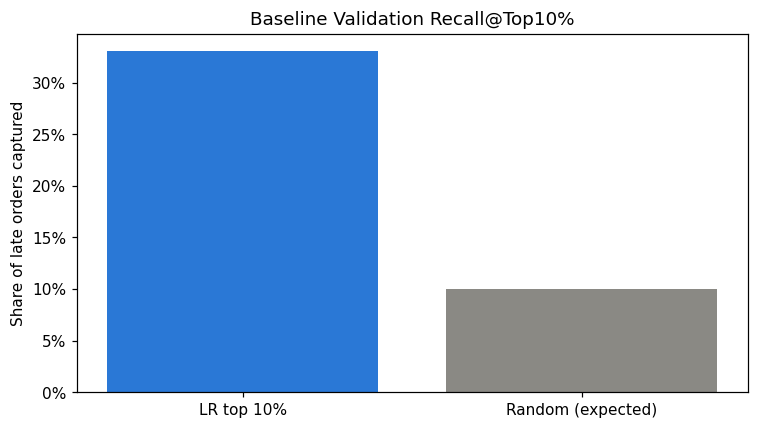

In [6]:
scores = validation_scores['Logistic Regression']
y_val = y_validation.to_numpy(dtype=int)
top = top_risk_indices(scores)
k = len(top)
captured = int(y_val[top].sum())
late_total = int(y_val.sum())
selected_fraction = k / len(y_val)

selection_summary = pd.DataFrame([
    {'method': 'LR top 10%', 'selected_orders': k,
     'late_orders_found': captured, 'on_time_orders_selected': k - captured,
     'late_orders_missed': late_total - captured,
     'recall': captured / late_total, 'precision': captured / k},
    {'method': 'Random selection (expected)', 'selected_orders': k,
     'late_orders_found': k * y_val.mean(),
     'on_time_orders_selected': k * (1 - y_val.mean()),
     'late_orders_missed': late_total * (1 - selected_fraction),
     'recall': selected_fraction, 'precision': y_val.mean()},
]).set_index('method')
display(selection_summary.round(4))

predicted = (scores >= 0.50).astype(int)
cm = confusion_matrix(y_val, predicted, labels=[0, 1])
display(pd.DataFrame(cm,
    index=['Actually on time', 'Actually late'],
    columns=['Predicted on time', 'Predicted late']))

print(f'Top-10% rule: {captured:,} of {late_total:,} late orders found.')
print(f'Top-10% precision: {captured / k:.2%}.')
print(f'0.50 threshold flags {predicted.sum():,} orders ({predicted.mean():.2%}).')
print(f"Validation PR-AUC (AP): {results.iloc[0]['PR-AUC (AP)']:.4f}; "
      f'validation late rate: {y_val.mean():.2%}.')

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(['LR top 10%', 'Random (expected)'],
       [captured / late_total, selected_fraction], color=['#2a78d6', '#8a8984'])
ax.set_ylabel('Share of late orders captured')
ax.set_title('Baseline Validation Recall@Top10%')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
fig.tight_layout()
plt.show()

### Interpretation

The baseline finds 210 of 635 late orders by selecting 1,427 of 14,266 validation orders. Recall@Top10% is 33.07%; precision in that selection is 14.72%.

Random selection of the same size would find about 64 late orders on average. LR provides useful prioritization, but it still misses 425 late orders and selects 1,217 on-time orders.

AP is 0.1135, above the validation late rate of 4.45%. These results show a ranking signal, not highly accurate individual predictions or a final deployment decision.

## 7. Two planned models

| Model | Plan | Main trade-off |
|---|---|---|
| XGBoost | Learn nonlinear effects and interactions among state, freight, and promised days | Needs tuning; harder to explain than LR |
| Stacking: LR + XGBoost | Train a second-level LR to combine predictions from the two base models | May use complementary signals; adds complexity and can overfit |

Neither planned model is implemented here. Improvement is not guaranteed. Stacking different models addresses the FAQ description of ensemble difficulty credit; credit depends on the final implementation and course assessment.

### Time-safe stacking plan

Within the training period, fit base models on earlier blocks and score later blocks. Train the second-level model only on these out-of-time predictions and their labels. Do not train it on in-sample base-model predictions.

Refit the base models on the eligible training data, keep the second-level model fixed, and score the later validation period. Check when historical delivery labels became available before each training boundary. Do not use the default random or stratified folds without adapting them to time order.

## 8. Final evaluation plan

Gexiang Zhang owns further model development. Ziqi Shang owns final evaluation.

1. Agree on the final time split and label-availability rules. Apply the same eligible orders and input features to each model. If the split changes, rerun the baseline too.
2. Choose model settings on training and validation data. Use Recall@Top10% as primary and AP as secondary. Select any classification threshold on validation data, not the test set.
3. Freeze model settings, preprocessing, ranking rules, and thresholds before test scoring. The current baseline remains fitted on training data only. Any later refit must be documented consistently for all models.
4. Score the test features and compare predictions with test labels. Report Recall@Top10%, AP, ROC-AUC, precision, recall, F1, and order counts.
5. Compare top-10% selection with random selection of the same size. Report Lift@Top10% = top-selection recall / selected fraction. Equivalently, divide top-selection precision by the evaluation-set late rate.
6. Report uncertainty, for example with time-block bootstrap intervals, and check performance across time periods and customer states. Do not tune models after seeing test results.

Final model comparisons, Lift, evaluation charts, and business conclusions are left for Ziqi Shang.

### Limits

- The dataset includes only delivered orders with valid timestamps and shipment after approval. Canceled and undelivered orders are outside this analysis.
- Historical shipment-based filtering can create selection bias.
- The initial split orders records by approval time. It does not yet ensure all training outcomes were known at validation start. Check label availability and a suitable time gap before final evaluation.
- EDA and hypothesis testing already used the full dataset. The test period is held out from model fitting, but it was not fully unseen during project exploration.
- Performance can change over time. Associations do not establish causal effects.

## 9. Project management

### Current progress

- Data cleaning and features: completed in notebook 01.
- EDA: completed in notebook 02.
- Two hypothesis tests and robustness checks: completed in notebook 03.
- LR baseline and initial validation: completed here.
- XGBoost, stacking, and final evaluation: planned.

### Responsibilities and timeline

| Stage | Task | Owner | Timing |
|---|---|---|---|
| Check-in preparation | Explain baseline results, two planned models, and next steps | Gexiang Zhang | Before November 17 meeting |
| Model development | Improve LR, implement XGBoost and time-safe stacking, and tune models | Gexiang Zhang | After meeting, before evaluation handoff |
| Model handoff | Provide pipelines, feature definitions, split boundaries, and model settings | Gexiang Zhang | After model development |
| Evaluation setup | Define label availability, time gap, comparison rules, and metrics | Ziqi Shang | Before final evaluation |
| Model adjustments | Apply any agreed split changes and refit all models consistently | Gexiang Zhang | Before final test scoring |
| Final evaluation | Test-set metrics, thresholds fixed on validation, uncertainty, and subgroup checks | Ziqi Shang | After model handoff |
| Business evaluation | Random-selection comparison, Lift, and top-10% prioritization | Ziqi Shang | During final evaluation |
| Results handoff | Evaluation tables, charts, and limitations for the final report | Ziqi Shang | Before final submission |

The final submission date and exact internal deadlines are to be confirmed. Other report and presentation tasks are not assigned here.

### Meeting preparation

Each member should explain the target, feature availability, time split, baseline results, model choices, evaluation rules, and next steps. Only the baseline is required to be implemented for this check-in; the two additional models are plans.